In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

# Display first 5 rows
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# 2. Check for missing values
print("\n--- Missing Values Check ---")
print(df.isnull().sum())

# 3. Prepare features (X) and target (y)
X = iris.data
y = iris.target

# 4. Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Feature Scaling (important for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

--- First 5 Rows of the Dataset ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



--- Missing Values Check ---
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Training set shape: (120, 4)
Testing set shape: (30, 4)


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model 1: Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train) # Decision trees don't strictly require scaled data

# Model 2: K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train) # KNN benefits from scaled data

print("Models successfully trained!")

Models successfully trained!


Decision Tree Accuracy: 93.33%
K-Nearest Neighbors Accuracy: 93.33%



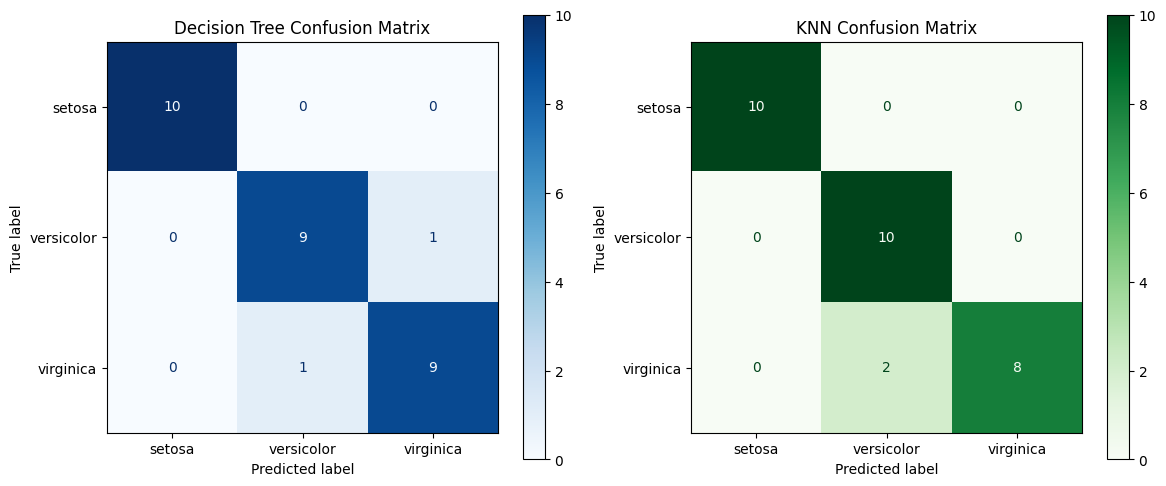

In [3]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test_scaled)

# Accuracies
acc_dt = accuracy_score(y_test, y_pred_dt)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"Decision Tree Accuracy: {acc_dt * 100:.2f}%")
print(f"K-Nearest Neighbors Accuracy: {acc_knn * 100:.2f}%\n")

# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, display_labels=iris.target_names, ax=axes[0], cmap='Blues')
axes[0].set_title("Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=iris.target_names, ax=axes[1], cmap='Greens')
axes[1].set_title("KNN Confusion Matrix")

plt.tight_layout()
plt.show()